In [5]:
print("hi")

hi


# online sales analysis

## part 1- data loading

### Import required libraries

In [6]:
import pandas as pd 
import matplotlib.pyplot as plt


### Load the CSV dataset using Pandas

In [7]:
import pandas as pd
df = pd.read_excel("C:/Users/Dell/Downloads/AEX/Project1/sales_data_2000_rows (2).xlsx")

In [8]:
df.head()

,Order_ID,Date,Product,Category,City,Quantity,Price
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624


### Check dataset information

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  2000 non-null   int64  
 1   Date      2000 non-null   str    
 2   Product   2000 non-null   str    
 3   Category  2000 non-null   str    
 4   City      2000 non-null   str    
 5   Quantity  1999 non-null   float64
 6   Price     2000 non-null   int64  
dtypes: float64(1), int64(2), str(4)
memory usage: 109.5 KB


## Part 2 — Data Cleaning

### Check missing values

In [ ]:
df.isnull().sum()

Order_ID    0
Date        0
Product     0
Category    0
City        0
Quantity    1
Price       0
dtype: int64

### Remove duplicate records

In [11]:
df.drop_duplicates

<bound method DataFrame.drop_duplicates of       Order_ID        Date   Product     Category       City  Quantity  Price
0         1001  2025-02-19   Printer  Electronics    Kolkata       3.0   9591
1         1002  2025-08-08       Pen   Stationery  Hyderabad       5.0    318
2         1003  2025-07-28     Mouse  Electronics    Chennai       1.0    697
3         1004  2025-08-15     Chair    Furniture  Ahmedabad       1.0   3410
4         1005  2025-04-12     Mouse  Electronics     Mumbai       NaN    624
...        ...         ...       ...          ...        ...       ...    ...
1995      2996  2025-12-26      Sofa    Furniture  Ahmedabad       4.0  15124
1996      2997  2025-02-27  Notebook   Stationery  Ahmedabad       3.0    160
1997      2998  2025-04-25     Chair    Furniture      Delhi       3.0   3590
1998      2999  2025-10-18   Monitor  Electronics     Mumbai       2.0   8550
1999      3000  2025-05-29       Bag  Accessories    Kolkata       5.0   1220

[2000 rows x 7 colum

### Correct spelling mistakes if any

In [ ]:
from textblob import TextBlob

### Convert Date column into datetime format

In [13]:
df['Date']=pd.to_datetime(df['Date'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Order_ID  2000 non-null   int64         
 1   Date      2000 non-null   datetime64[us]
 2   Product   2000 non-null   str           
 3   Category  2000 non-null   str           
 4   City      2000 non-null   str           
 5   Quantity  1999 non-null   float64       
 6   Price     2000 non-null   int64         
dtypes: datetime64[us](1), float64(1), int64(2), str(3)
memory usage: 109.5 KB


## Part 3 — Data Processing

In [18]:
df["Revenue"] = df["Quantity"] * df["Price"]
df.head()

,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591,28773.0
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318,1590.0
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697,697.0
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410,3410.0
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624,NaN


## Part 4 — Data Analysis 

###  Total Revenue

In [20]:
total_revenue = df["Revenue"].sum()
print("Total Revenue:", total_revenue)

Total Revenue: 51500062.0


###  Best Selling Product

In [24]:
product_sales = df.groupby("Product") ["Quantity"].sum()
best_selling_product = product_sales. idxmax()
print("Best selling product:", best_selling_product)
print("Total Quantity Sold:", product_sales. idxmax)


Best selling product: Chair
Total Quantity Sold: <bound method Series.idxmax of Product
Bag         529.0
Bottle      497.0
Chair       568.0
Keyboard    509.0
Laptop      492.0
Monitor     476.0
Mouse       457.0
Notebook    531.0
Pen         507.0
Printer     517.0
Sofa        537.0
Table       449.0
Name: Quantity, dtype: float64>


###  Best Performing City

In [28]:
city_revenue = df.groupby("City")["Revenue"].sum()
best_city = city_revenue.idxmax()
print("Best Performing City:", best_city)
print("Total Revenue:", city_revenue.max())

Best Performing City: Ahmedabad
Total Revenue: 7449911.0


### Category Analysis


In [30]:
category_revenue = df.groupby("Category")["Revenue"].sum()
print(category_revenue)

Category
Accessories      905769.0
Electronics    37093350.0
Furniture      13343784.0
Stationery       157159.0
Name: Revenue, dtype: float64


###  Monthly Sales Analysis

In [31]:
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.to_period("M")

monthly_revenue = df.groupby("Month")["Revenue"].sum()
print(monthly_revenue)

Month
2025-01    4021909.0
2025-02    3655339.0
2025-03    4607846.0
2025-04    4783602.0
2025-05    4884091.0
2025-06    3654206.0
2025-07    3979183.0
2025-08    4012286.0
2025-09    4318017.0
2025-10    4428577.0
2025-11    4185989.0
2025-12    4891185.0
2026-01      77832.0
Freq: M, Name: Revenue, dtype: float64


## Part 5 — Data Visualization

### Bar Chart: Revenue by City

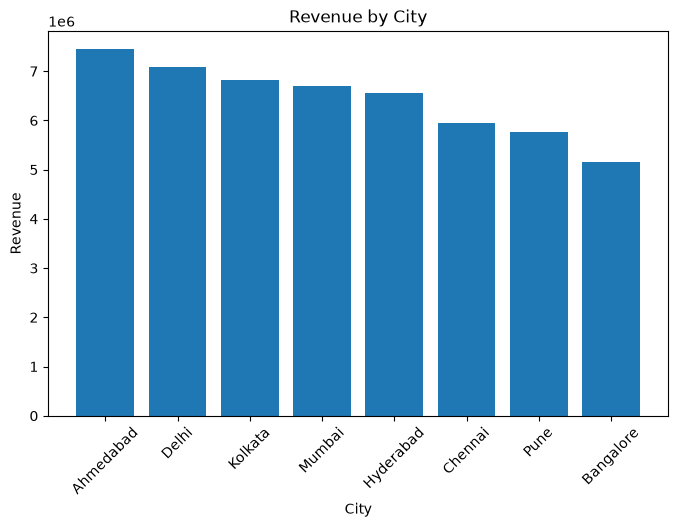

In [33]:
city_revenue = df.groupby('City')['Revenue'].sum().sort_values(ascending=False)
plt.figure(figsize=(8, 5))
plt.bar(city_revenue.index, city_revenue.values)
plt.title('Revenue by City')
plt.xlabel('City')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

### Pie Chart- Category contribution

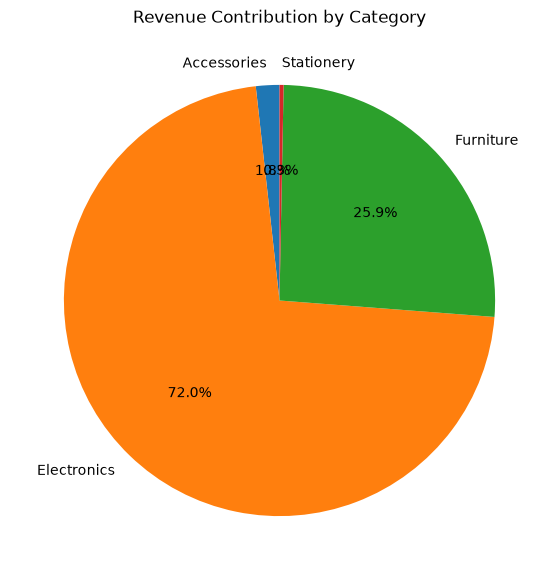

In [34]:
category_revenue = df.groupby('Category')['Revenue'].sum()
plt.figure(figsize=(7, 7))
plt.pie(category_revenue.values, labels=category_revenue.index, autopct='%1.1f%%', startangle=90)
plt.title('Revenue Contribution by Category')
plt.show()

### Line Chart-  Monthly sales trend

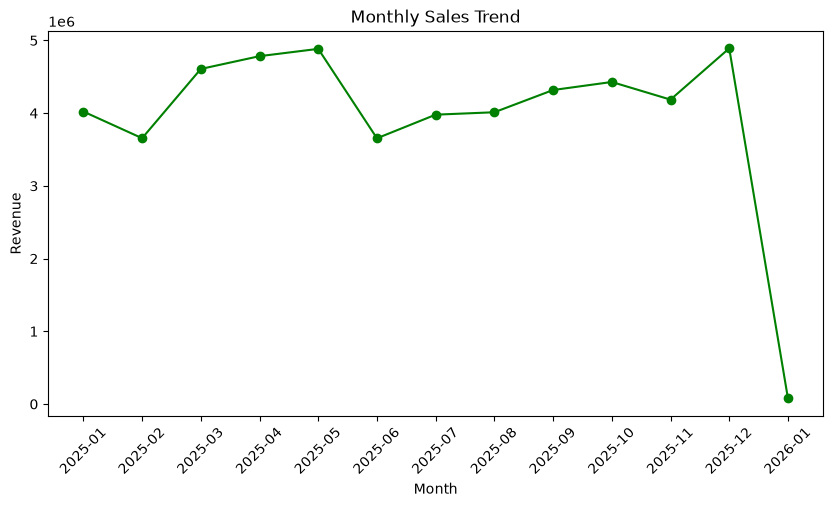

In [35]:
df['Month'] = df['Date'].dt.to_period('M')
monthly_revenue = df.groupby('Month')['Revenue'].sum()
plt.figure(figsize=(10, 5))
plt.plot(monthly_revenue.index.astype(str), monthly_revenue.values, marker='o', color='green')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

## Part 6 — Business Insights

1. Total Revenue

The company generated a total revenue of ₹5,15,00,062 from its sales.

2. Highest Revenue Category

Electronics generated the highest revenue of ₹3,70,93,350 among all product categories.

3. Second Highest Revenue Category

Furniture generated ₹1,33,43,784, making it the second-highest revenue-generating category.

4. Best Performing City

Ahmedabad recorded the highest revenue of ₹74,49,911 among all cities.

5. Best-Selling Product

Chair was the best-selling product based on the total quantity sold.

6. Highest Sales Month

December 2025 generated the highest monthly revenue of ₹48,91,185.

7. Lowest Sales Month

January 2026 recorded the lowest monthly revenue of ₹77,832. This may be because the dataset contains fewer records for that month.

## Part 7 — Recommendations

1. Increase Marketing for Electronics Products

Since Electronics generated the highest revenue, the company should increase advertisements and promotional activities for Electronics products to improve sales further.

2. Promote Furniture Products

Furniture generated the second-highest revenue. The company should introduce attractive offers and discounts to increase Furniture sales.

3. Improve Marketing in Low-Performing Cities

The company should focus on cities with lower revenue, such as Bangalore, by introducing special offers and targeted marketing campaigns.

4. Maintain Stock of Best-Selling Products

Since Chairs recorded the highest quantity sold, the company should maintain sufficient stock to meet customer demand and avoid stock shortages.

5. Introduce Offers During Low-Sales Months

The company can introduce seasonal discounts and promotional campaigns during low-sales periods to improve monthly revenue.